Implement a simple character-level RNN/LSTM for text generation (e.g., generating Shakespearean text)

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ==========================================
# 1. Load downloaded Shakespeare file
# ==========================================

text = open("C:/Users/HP/Downloads/shakespeare.txt", "r", encoding="utf-8").read()

# Use only 100000 characters for faster training
text = text[:100000]

print("Text length:", len(text))


Text length: 305


In [2]:
# ==========================================
# 2. Character encoding
# ==========================================

chars = sorted(set(text))

char_to_int = {
    c: i for i, c in enumerate(chars)
}

int_to_char = np.array(chars)

encoded = np.array([
    char_to_int[c] for c in text
])

print("Number of characters:", len(chars))

Number of characters: 34


In [3]:
# ==========================================
# 3. Create sequences
# ==========================================

seq_length = 50

X = []
y = []

for i in range(len(encoded) - seq_length):

    X.append(
        encoded[i:i + seq_length]
    )

    y.append(
        encoded[i + seq_length]
    )

X = np.array(X)
y = np.array(y)

# Use only 20000 sequences
X = X[:20000]
y = y[:20000]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (255, 50)
y shape: (255,)


In [4]:
# ==========================================
# 4. Create LSTM model
# ==========================================

model = tf.keras.Sequential([

    tf.keras.layers.Embedding(
        len(chars),
        32
    ),

    tf.keras.layers.LSTM(
        64
    ),

    tf.keras.layers.Dense(
        len(chars),
        activation="softmax"
    )
])

In [5]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# ==========================================
# 6. Train
# ==========================================

history = model.fit(
    X,
    y,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 741ms/step - accuracy: 0.0262 - loss: 3.5259 - val_accuracy: 0.0769 - val_loss: 3.5206
Epoch 2/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.1397 - loss: 3.5171 - val_accuracy: 0.1154 - val_loss: 3.5132
Epoch 3/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accuracy: 0.1528 - loss: 3.5065 - val_accuracy: 0.1154 - val_loss: 3.5036
Epoch 4/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.1572 - loss: 3.4930 - val_accuracy: 0.1154 - val_loss: 3.4897
Epoch 5/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.1572 - loss: 3.4714 - val_accuracy: 0.1154 - val_loss: 3.4673


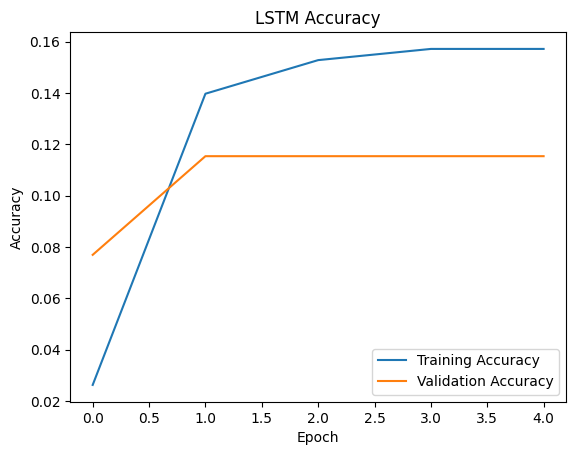

In [6]:
# ==========================================
# 7. Accuracy plot
# ==========================================

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title("LSTM Accuracy")

plt.legend()

plt.show()

In [7]:
prediction = model.predict(
    X[:100],
    verbose=0
)

predicted = np.argmax(
    prediction,
    axis=1
)

actual = y[:100]

print("\nActual characters:")
print(
    "".join(int_to_char[actual])
)

print("\nPredicted characters:")
print(
    "".join(int_to_char[predicted])
)


Actual characters:
food tasted terrible and was cold.\t0
This is the best book I have ever read.\t1
I am so disappointe

Predicted characters:
                                                                                                    


In [8]:
print("\n======================")
print("LSTM METRICS")
print("======================")

print(
    "Accuracy :",
    accuracy_score(actual, predicted)
)

print(
    "Precision:",
    precision_score(
        actual,
        predicted,
        average="weighted",
        zero_division=0
    )
)

print(
    "Recall   :",
    recall_score(
        actual,
        predicted,
        average="weighted",
        zero_division=0
    )
)

print(
    "F1 Score :",
    f1_score(
        actual,
        predicted,
        average="weighted",
        zero_division=0
    )
)


LSTM METRICS
Accuracy : 0.16
Precision: 0.0256
Recall   : 0.16
F1 Score : 0.044137931034482755


Number of characters: 34
X shape: (255, 50)
y shape: (255,)


c:\Users\VICTUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 428ms/step - accuracy: 0.0524 - loss: 3.5187 - val_accuracy: 0.0385 - val_loss: 3.5273
Epoch 2/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.1572 - loss: 3.3653 - val_accuracy: 0.0000e+00 - val_loss: 3.4832
Epoch 3/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.2271 - loss: 3.2397 - val_accuracy: 0.0769 - val_loss: 3.4558
Epoch 4/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step - accuracy: 0.2489 - loss: 3.1275 - val_accuracy: 0.0385 - val_loss: 3.3986
Epoch 5/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 296ms/step - accuracy: 0.2751 - loss: 3.0065 - val_accuracy: 0.0769 - val_loss: 3.3875


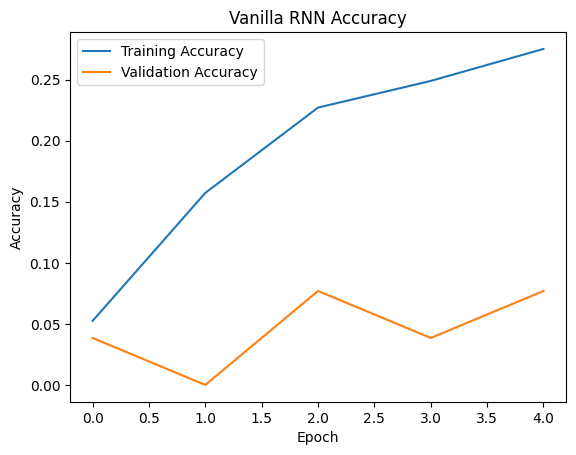

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Dense, Embedding, SimpleRNN
from tensorflow.keras.models import Sequential

# Dummy text placeholder (Replace this with your actual 'text' variable)
text = open("file.txt", encoding="utf-8").read()

# ==========================================
# 2. Character encoding
# ==========================================
chars = sorted(set(text))
vocab_size = len(chars)

char_to_int = {c: i for i, c in enumerate(chars)}
int_to_char = np.array(chars)
encoded = np.array([char_to_int[c] for c in text])

print("Number of characters:", vocab_size)

# ==========================================
# 3. Create sequences
# ==========================================
seq_length = 50
X = []
y = []

for i in range(len(encoded) - seq_length):
    X.append(encoded[i : i + seq_length])
    y.append(encoded[i + seq_length])

X = np.array(X)
y = np.array(y)

# Use only 20000 sequences
X = X[:20000]
y = y[:20000]

print("X shape:", X.shape)
print("y shape:", y.shape)

# ==========================================
# 4. Model Definition (Using SimpleRNN)
# ==========================================
embedding_dim = 64
rnn_units = 128

model = Sequential(
    [
        # Layer 1: Vectorizes character IDs
        Embedding(
            input_dim=vocab_size, output_dim=embedding_dim, input_length=seq_length
        ),
        # Layer 2: Vanilla Recurrent Neural Network
        SimpleRNN(rnn_units, return_sequences=False),
        # Layer 3: Maps outputs to character probabilities
        Dense(vocab_size),
    ]
)

# ==========================================
# 5. Model Compilation
# ==========================================
model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

model.summary()

# ==========================================
# 6. Train
# ==========================================
history = model.fit(X, y, epochs=5, batch_size=128, validation_split=0.1)

# ==========================================
# 7. Accuracy plot
# ==========================================
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Vanilla RNN Accuracy")
plt.legend()
plt.show()
